# Question 3: Function Approximation Using Feedforward Neural Networks

In this experiment, two feedforward neural networks (FFNs) are trained using Keras to approximate nonlinear mathematical functions.

The first model learns the sine function over the training interval (-π, π). Its behavior outside the training range is then evaluated over (π, 2π).

The second model learns a different nonlinear function to further investigate the function approximation capability of neural networks.

#3.1 Model-1

## Model 1: Sine Function Approximation

For the first FFN model, the target function is

$$
f(x)=\sin(x)
$$

The model is trained using data from the interval $(-\pi,\pi)$. After training, its performance is evaluated within the training domain and then on the unseen interval $(\pi,2\pi)$ to examine its extrapolation ability.

###3.1.1 Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

###3.1.2 Generate the Data

In [57]:
# Define the sine function
def sine_function(x):
    return np.sin(x)


# Generate 1000 evenly spaced points from -pi to pi
x_1 = np.linspace(-np.pi, np.pi, 1000)

# Calculate the corresponding sine values
y_1 = sine_function(x_1)


# Reshape both arrays for Keras
x_1 = x_1.reshape(-1, 1)
y_1 = y_1.reshape(-1, 1)


print("Shape of x:", x_1.shape)
print("Shape of y:", y_1.shape)

Shape of x: (1000, 1)
Shape of y: (1000, 1)


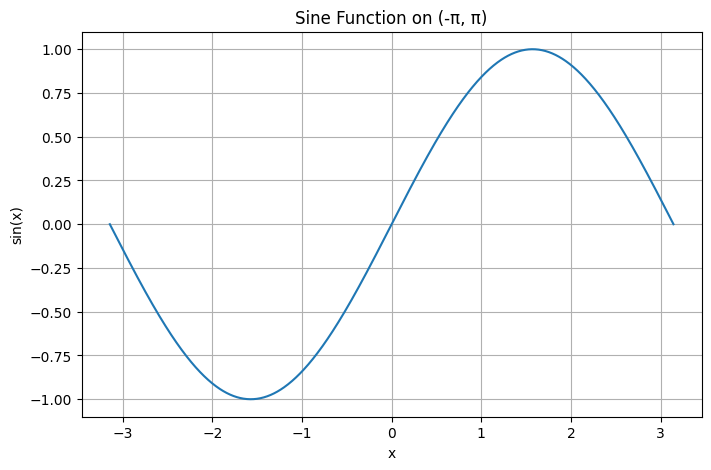

In [58]:
plt.figure(figsize=(8, 5))

plt.plot(x_1, y_1)

plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("Sine Function on (-π, π)")
plt.grid(True)

plt.show()

###3.1.3 Random Train/Validation Split

In [59]:
from sklearn.model_selection import train_test_split

x_train_1, x_val_1, y_train_1, y_val_1 = train_test_split(
    x_1,
    y_1,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(x_train_1))
print("Validation samples:", len(x_val_1))

Training samples: 800
Validation samples: 200


###3.1.4 Build Model 1

In [60]:
tf.keras.backend.clear_session()

np.random.seed(42)
tf.random.set_seed(42)

In [61]:
model_1 = keras.Sequential([
    layers.Input(shape=(1,)),

    layers.Dense(32, activation="tanh"),
    layers.Dense(32, activation="tanh"),

    layers.Dense(1)
])

###3.1.5 Compile Model

In [62]:
model_1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

In [63]:
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

###3.1.6 Early Stopping

In [64]:
early_stopping_1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=100,
    restore_best_weights=True
)

###3.1.7 Train Model 1

In [65]:
history_1 = model_1.fit(
    x_train_1,
    y_train_1,
    validation_data=(x_val_1, y_val_1),
    epochs=2000,
    batch_size=32,
    callbacks=[early_stopping_1],
    verbose=0
)

In [66]:
print("Number of epochs trained:", len(history_1.history["loss"]))
print("Final training loss:", history_1.history["loss"][-1])
print("Best validation loss:", min(history_1.history["val_loss"]))

Number of epochs trained: 392
Final training loss: 1.7413482055417262e-05
Best validation loss: 9.05824163055513e-06


###3.1.8 Training and Validation Loss

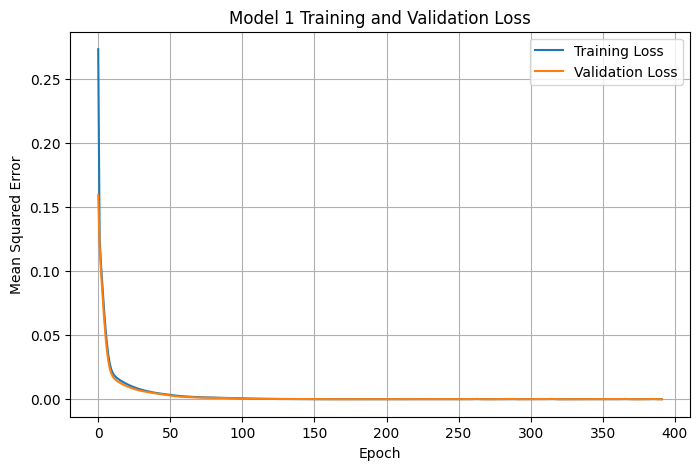

In [67]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_1.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_1.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Model 1 Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

###3.1.9 Prediction Within Training Domain

In [77]:
y_pred_1 = model_1.predict(
    x_1,
    verbose=0
)

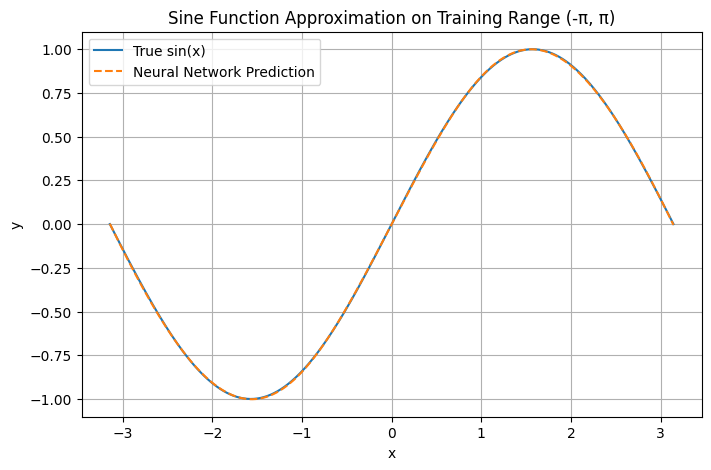

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(
    x_1,
    y_1,
    label="True sin(x)"
)

plt.plot(
    x_1,
    y_pred_1,
    "--",
    label="Neural Network Prediction"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Sine Function Approximation on Training Range (-π, π)"
)

plt.legend()
plt.grid(True)

plt.show()

Within the training domain $(-\pi,\pi)$, the neural network prediction almost completely overlaps the true sine curve. This demonstrates that the FFN has sufficient capacity to accurately approximate the nonlinear sine function over the domain represented by the training data.

###3.1.10 Extrapolation Data

### Extrapolation Outside the Training Domain

The FFN was trained only on samples from $(-\pi,\pi)$. To evaluate its behavior outside the observed domain, the trained model is tested on the unseen interval

$$
x\in(\pi,2\pi).
$$

The predicted mapping is compared with the true sine function.

In [79]:
x_extra_1 = np.linspace(
    np.pi,
    2 * np.pi,
    500
).reshape(-1, 1)

y_extra_true_1 = sine_function(x_extra_1)

In [80]:
y_extra_pred_1 = model_1.predict(
    x_extra_1,
    verbose=0
)

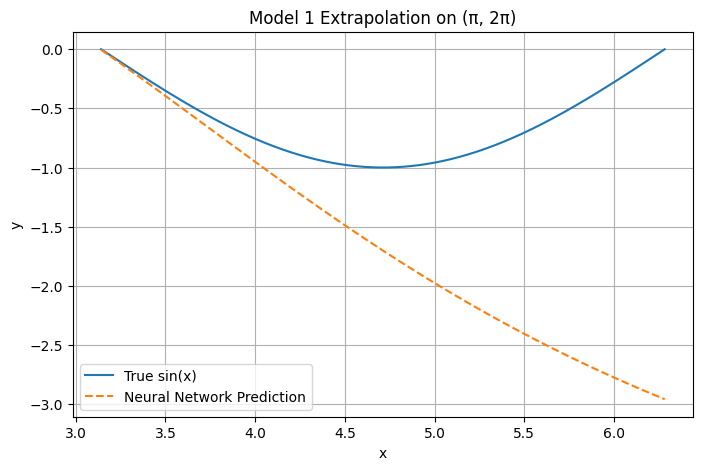

In [81]:
plt.figure(figsize=(8, 5))

plt.plot(
    x_extra_1,
    y_extra_true_1,
    label="True sin(x)"
)

plt.plot(
    x_extra_1,
    y_extra_pred_1,
    "--",
    label="Neural Network Prediction"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Model 1 Extrapolation on (π, 2π)"
)

plt.legend()
plt.grid(True)

plt.show()

Despite its excellent performance within the training domain, the model performs poorly when extrapolating to the unseen interval $(\pi,2\pi)$.

Near $x=\pi$, the prediction initially remains close to the true sine function. However, as $x$ moves farther from the training boundary, the prediction increasingly deviates from the true function. Instead of reproducing the periodic behavior of the sine wave and returning toward zero, the predicted values continue to decrease.

This indicates that the FFN successfully learned an approximation of the sine function within the observed domain, but it did not learn the underlying periodic mathematical rule. Therefore, strong interpolation performance does not necessarily imply accurate extrapolation.

### Model 1 Results

The sine FFN was trained for 392 epochs before early stopping. It achieved a final training MSE of approximately $1.74 \times 10^{-5}$ and a best validation MSE of approximately $9.06 \times 10^{-6}$.

Both the training and validation losses decreased rapidly and converged to values close to zero. The two loss curves remained close throughout training, suggesting that the model converged successfully without noticeable overfitting.

#3.2 Model-2 — Non-Trivial Function

For the second experiment, the nonlinear function

f(x) = sin(x) + 0.3 cos(3x)

is used. This function combines two periodic components with different frequencies, making it more complex than the sine function used in the first experiment.

The model is trained over the interval (-π, π), and its ability to approximate the function both within and outside the training domain is evaluated.

In [34]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

keras.backend.clear_session()

np.random.seed(42)
tf.random.set_seed(42)

###3.2.1 Generate data

In [39]:
# Define the second target function
def target_function(x):
    return np.sin(x) + 0.3 * np.cos(3 * x)


# Generate 1000 evenly spaced points from -pi to pi
x_2 = np.linspace(-np.pi, np.pi, 1000)

# Calculate the corresponding function values
y_2 = target_function(x_2)


# Reshape both arrays for Keras
x_2 = x_2.reshape(-1, 1)
y_2 = y_2.reshape(-1, 1)


print("Shape of x:", x_2.shape)
print("Shape of y:", y_2.shape)

Shape of x: (1000, 1)
Shape of y: (1000, 1)


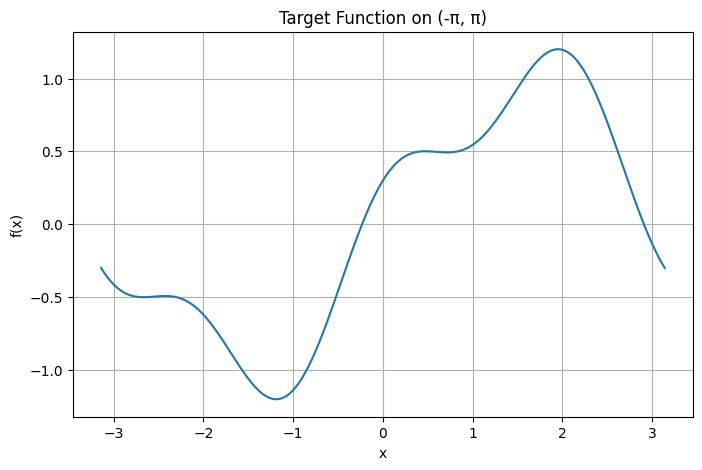

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(x_2, y_2)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Target Function on (-π, π)")
plt.grid(True)

plt.show()

###3.2.2 Random Train/Validation Split

In [41]:
from sklearn.model_selection import train_test_split

x_train_2, x_val_2, y_train_2, y_val_2 = train_test_split(
    x_2,
    y_2,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(x_train_2))
print("Validation samples:", len(x_val_2))


Training samples: 800
Validation samples: 200


###3.2.3 Build Model-2

In [42]:
tf.keras.backend.clear_session()

np.random.seed(42)
tf.random.set_seed(42)

In [43]:
model_2 = keras.Sequential([
    layers.Input(shape=(1,)),

    layers.Dense(32, activation="tanh"),
    layers.Dense(32, activation="tanh"),
    layers.Dense(16, activation="tanh"),

    layers.Dense(1)
])

In [46]:
model_2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

In [47]:
model_2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,665 (6.50 KB)

 Trainable params: 1,665 (6.50 KB)

 Non-trainable params: 0 (0.00 B)

###3.2.4 Early Stopping

In [48]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=100,
    restore_best_weights=True
)

###3.2.5 Train Model-2

In [49]:
history_2 = model_2.fit(
    x_train_2,
    y_train_2,
    validation_data=(x_val_2, y_val_2),
    epochs=2000,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

In [50]:
print("Number of epochs trained:", len(history_2.history["loss"]))
print("Final training loss:", history_2.history["loss"][-1])
print("Best validation loss:", min(history_2.history["val_loss"]))

Number of epochs trained: 306
Final training loss: 0.00046353525249287486
Best validation loss: 0.000437793176388368


###3.2.5 Training Loss

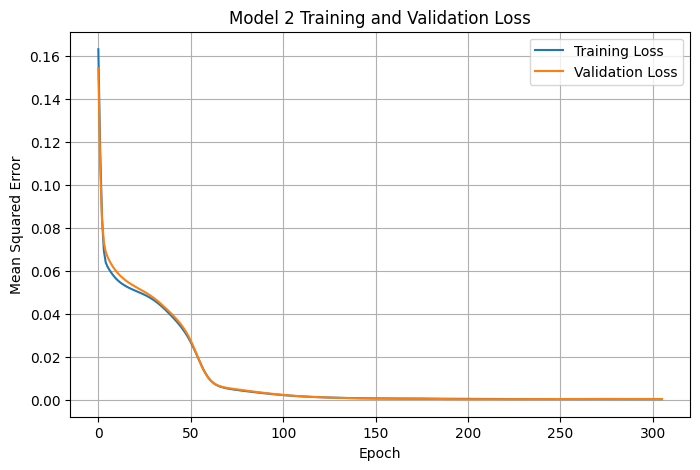

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_2.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_2.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Model 2 Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [52]:
y_pred_2 = model_2.predict(
    x_2,
    verbose=0
)

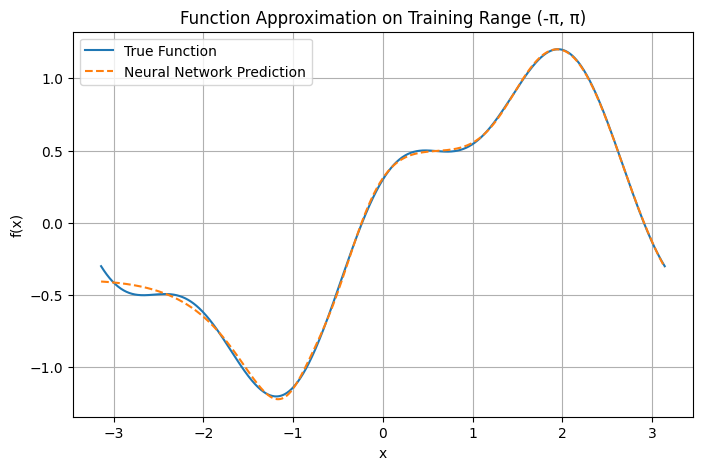

In [53]:
plt.figure(figsize=(8, 5))

plt.plot(x_2,y_2,label="True Function"
)

plt.plot(x_2,y_pred_2,"--",label="Neural Network Prediction"
)

plt.xlabel("x")
plt.ylabel("f(x)")

plt.title(
    "Function Approximation on Training Range (-π, π)"
)

plt.legend()
plt.grid(True)

plt.show()

###3.2.6 Model 2 Extrapolation on (π, 2π)

### Extrapolation Outside the Training Domain

The model was trained only on $x\in(-\pi,\pi)$. To examine whether the learned mapping generalizes beyond the observed domain, the trained model is evaluated on the unseen interval

$$
x\in(\pi,2\pi).
$$

In [54]:
x_extra_2 = np.linspace(
    np.pi,
    2 * np.pi,
    500
).reshape(-1, 1)

y_extra_true_2 = target_function(x_extra_2)

In [55]:
y_extra_pred_2 = model_2.predict(
    x_extra_2,
    verbose=0
)

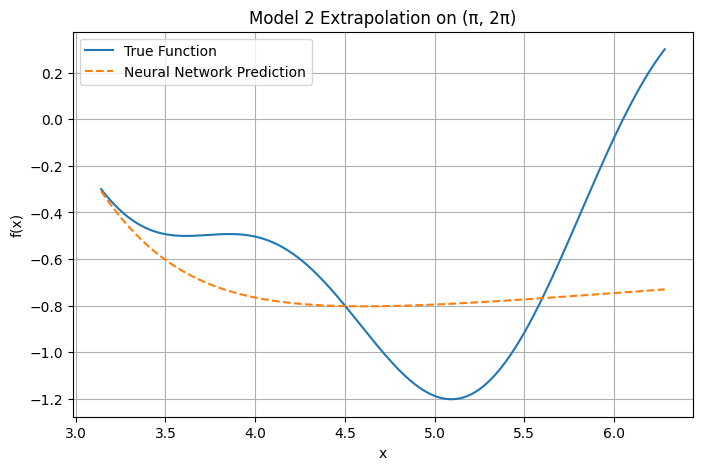

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(
    x_extra_2,
    y_extra_true_2,
    label="True Function"
)

plt.plot(
    x_extra_2,
    y_extra_pred_2,
    "--",
    label="Neural Network Prediction"
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Model 2 Extrapolation on (π, 2π)")
plt.legend()
plt.grid(True)
plt.show()

### Model 2 Results

The second FFN successfully approximated the nonlinear target function within the training domain $(-\pi,\pi)$. The model was trained for 306 epochs before early stopping, achieving a final training MSE of approximately 0.000464 and a best validation MSE of approximately 0.000438.

The training and validation loss curves decrease together and converge to values close to zero, with no substantial gap between them. This suggests that the model learned the underlying relationship without noticeable overfitting.

Within the training interval, the neural network prediction closely overlaps the true function, demonstrating that the FFN has sufficient capacity to approximate the more complex nonlinear mapping.

However, performance deteriorates outside the training domain. On the unseen interval $(\pi,2\pi)$, the predicted curve initially remains relatively close to the true function but increasingly deviates as $x$ moves farther from the training boundary. In particular, the model fails to reproduce the subsequent decrease and increase of the true periodic function. This demonstrates that strong interpolation performance does not necessarily imply successful extrapolation.

### Summary of Model Architectures and Results

| Component | Model 1: Sine Function | Model 2: Non-Trivial Function |
|---|---|---|
| Target Function | $\sin(x)$ | $\sin(x)+0.3\cos(3x)$ |
| Input Layer | 1 | 1 |
| Hidden Layer 1 | 32, Tanh | 32, Tanh |
| Hidden Layer 2 | 32, Tanh | 32, Tanh |
| Hidden Layer 3 | - | 16, Tanh |
| Output Layer | 1, Linear | 1, Linear |
| Optimizer | Adam | Adam |
| Learning Rate | 0.001 | 0.001 |
| Loss Function | MSE | MSE |
| Batch Size | 32 | 32 |
| Train/Validation Split | 80/20 | 80/20 |
| Early Stopping | Yes | Yes |
| Epochs Trained | 392 | 306 |
| Final Training MSE | $1.74 \times 10^{-5}$ | $4.64 \times 10^{-4}$ |
| Best Validation MSE | $9.06 \times 10^{-6}$ | $4.38 \times 10^{-4}$ |

## Discussion: Universal Function Approximation

Based on these experiments, I agree that feedforward neural networks can act as universal function approximators, but this statement requires an important qualification.

Both models demonstrated strong function approximation within the domains represented by their training data. Model 1 reproduced the sine function almost perfectly over $(-\pi,\pi)$, while Model 2 also successfully approximated the more complex function $f(x)=\sin(x)+0.3\cos(3x)$. The very low training and validation errors indicate that the FFNs had sufficient representational capacity to learn both nonlinear mappings.

However, both models performed considerably worse outside the training domain. In particular, Model 1 failed to reproduce the periodic behavior of the sine function over $(\pi,2\pi)$, even though its approximation within the training interval was highly accurate. A similar deterioration in extrapolation performance was observed for Model 2.

Therefore, these experiments support the universal approximation capability of neural networks within a bounded domain, but they also demonstrate that universal approximation does not guarantee accurate extrapolation. The networks learned mappings from the observed training samples rather than the underlying analytical formulas or periodic structure of the functions. Their ability to approximate a function within the training domain should therefore be distinguished from their ability to generalize beyond that domain.